# Tech Challenge – Fase 1: Diagnóstico de câncer de mama com Machine Learning

**Problema.** Um hospital universitário quer um sistema de apoio ao diagnóstico. Nesta fase usamos a base pública
**Breast Cancer Wisconsin (Diagnostic)** ([Kaggle](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data/data) / UCI) para
classificar tumores de mama como **maligno (1)** ou **benigno (0)** a partir de 30 medidas extraídas de imagens digitalizadas de
punção aspirativa por agulha fina (PAAF): raio, textura, perímetro, área, suavidade, compacidade, concavidade, pontos côncavos,
simetria e dimensão fractal dos núcleos celulares, cada uma resumida como média (`_mean`), erro padrão (`_se`) e pior valor (`_worst`).

**Por que importa.** Um falso negativo (dizer benigno quando é maligno) atrasa o tratamento; por isso o **recall da classe maligna** é a métrica
principal. O modelo é uma **ferramenta de triagem**: o médico sempre tem a palavra final.

Fluxo: exploração → limpeza e pipeline → correlação → modelos (treino / validação / teste) → avaliação → interpretação (feature importance e SHAP) → discussão.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # permite importar src/ a partir de notebooks/
warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 40)
from src import eda, interpretation, modeling
from src.data import TARGET, load_raw
from src.preprocessing import clean, split
FIG = Path.cwd().parent / "results" / "figures"
eda.FIG_DIR = modeling.FIG_DIR = interpretation.FIG_DIR = FIG

## 1. Carregamento e exploração dos dados

In [2]:
raw = load_raw()
print(raw.shape)
raw.head()

(569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,M,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,M,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,M,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,M,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    str    
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave_points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  569 non-null

A base tem **569 pacientes** e 30 variáveis numéricas contínuas. Não há variáveis categóricas além do alvo (`diagnosis`, M/B).
Se o CSV do Kaggle for usado, ele também traz `id` (identificador) e `Unnamed: 32` (coluna vazia), removidas na limpeza.

In [4]:
df = clean(raw)
eda.summary(df)

{'linhas': 569,
 'colunas': 31,
 'valores_ausentes': 0,
 'duplicatas': 0,
 'distribuicao_alvo': {'Benigno': 357, 'Maligno': 212}}

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
diagnosis,569.0000,0.3726,0.4839,0.0000,0.0000,0.0000,1.0000,1.0000
radius_mean,569.0000,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100
texture_mean,569.0000,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800
perimeter_mean,569.0000,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000
area_mean,569.0000,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000
smoothness_mean,569.0000,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634
compactness_mean,569.0000,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454
concavity_mean,569.0000,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268
concave_points_mean,569.0000,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012
symmetry_mean,569.0000,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040


**Leitura das estatísticas.** As escalas são muito diferentes (ex.: `area_mean` vai de ~140 a ~2500, enquanto `smoothness_mean` fica
perto de 0,1), o que exige **padronização** para modelos sensíveis a escala (Regressão Logística, KNN). Várias variáveis têm média maior que a
mediana e máximos distantes, indicando **assimetria à direita** e outliers (tumores grandes), que são clinicamente plausíveis e por isso foram mantidos.

In [6]:
mean_cols = [c for c in df.columns if c.endswith("_mean")]
df.groupby(TARGET)[mean_cols].mean().T.rename(columns={0: "Benigno", 1: "Maligno"})

diagnosis,Benigno,Maligno
radius_mean,12.1465,17.4628
texture_mean,17.9148,21.6049
perimeter_mean,78.0754,115.3654
area_mean,462.7902,978.3764
smoothness_mean,0.0925,0.1029
compactness_mean,0.0801,0.1452
concavity_mean,0.0461,0.1608
concave_points_mean,0.0257,0.0880
symmetry_mean,0.1742,0.1929
fractal_dimension_mean,0.0629,0.0627


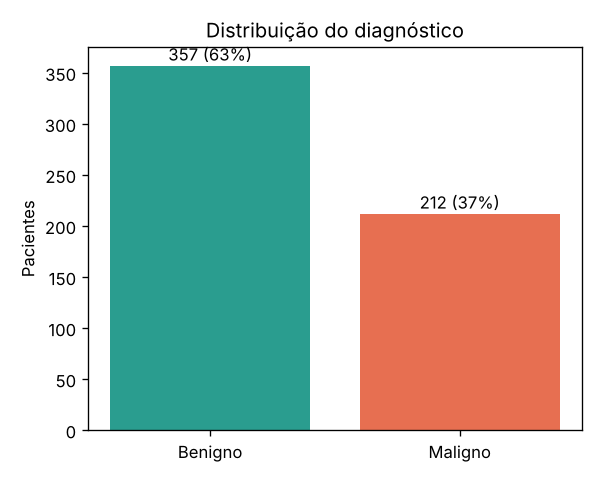

In [7]:
eda.plot_target(df); display(Image(FIG / "01_distribuicao_alvo.png"))

A classe maligna representa **~37%** dos casos: há desbalanceamento moderado. Por isso usamos divisão **estratificada** e testamos `class_weight="balanced"`.

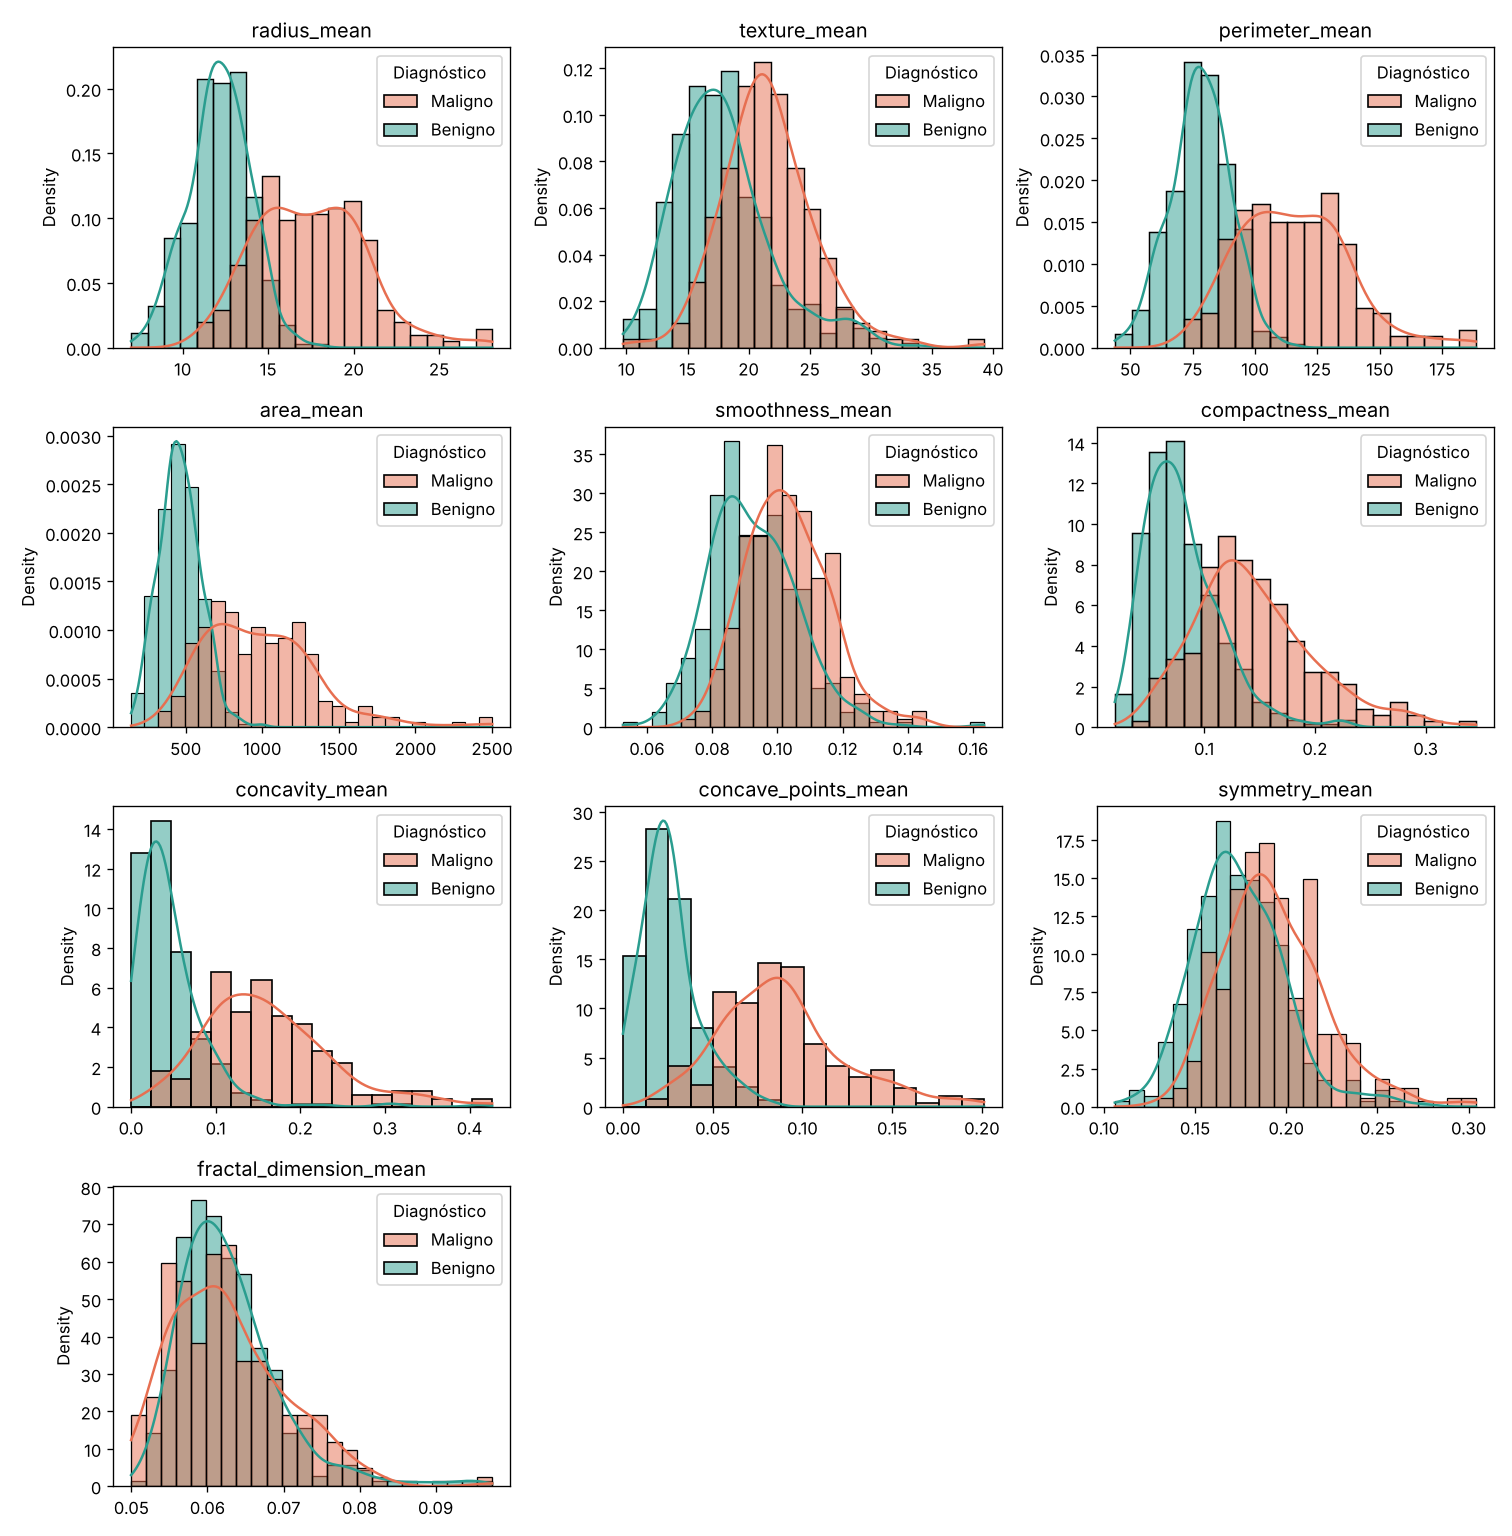

In [8]:
eda.plot_distributions(df, mean_cols); display(Image(FIG / "02_distribuicoes.png"))

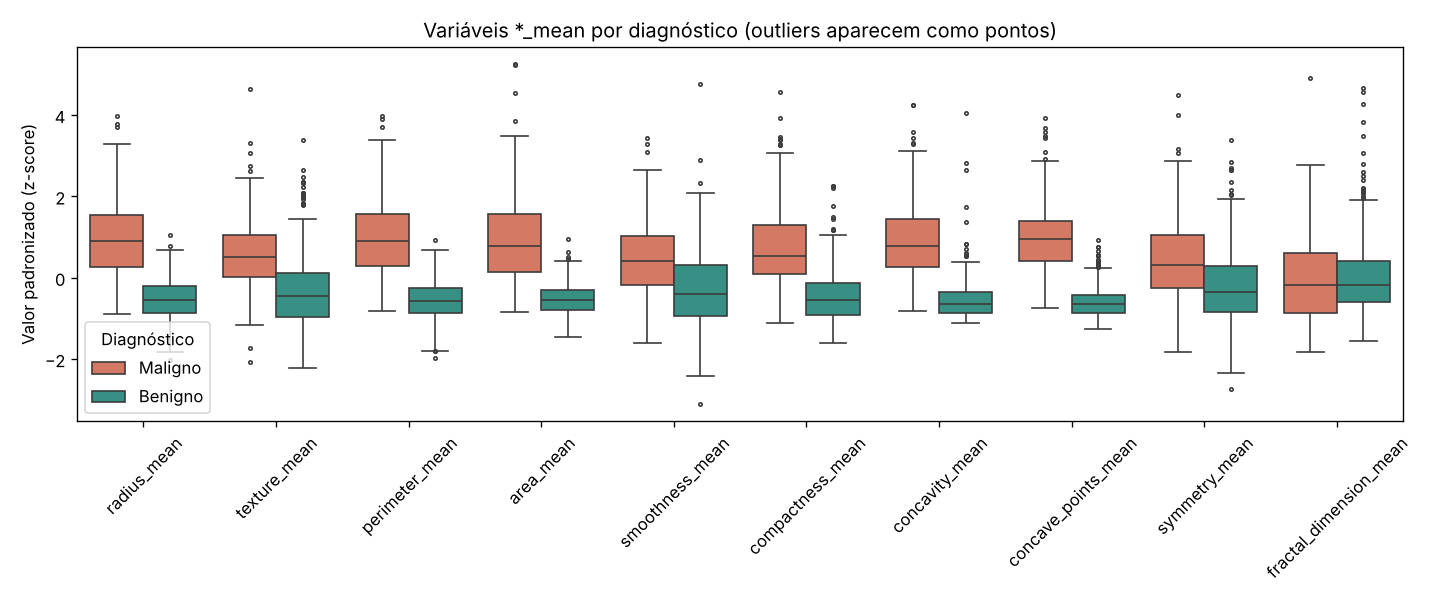

In [9]:
eda.plot_boxplots(df, mean_cols); display(Image(FIG / "03_boxplots.png"))

**Discussão.** Tumores malignos têm, em média, **raio, perímetro, área, concavidade e pontos côncavos bem maiores**; as distribuições quase
não se sobrepõem nessas variáveis. Já `fractal_dimension_mean`, `smoothness_mean` e `symmetry_mean` separam pouco as classes.

## 2. Pré-processamento

Estratégias aplicadas (código em `src/preprocessing.py`):

1. **Limpeza (`clean`)**: remove `id` e colunas vazias, remove duplicatas, converte o alvo M/B em 1/0, força as variáveis para numérico e trata
   valores **inconsistentes** (medidas negativas, impossíveis fisicamente) como ausentes.
2. **Valores ausentes**: a base não tem nenhum, mas o pipeline faz **imputação pela mediana** (robusta a outliers) para dados futuros.
3. **Padronização** (`StandardScaler`) das numéricas; **one-hot** para categóricas, se existirem (o pipeline é reutilizável em outras bases).
4. Tudo fica dentro de um `Pipeline` do scikit-learn **ajustado só no treino**, evitando *data leakage* para validação e teste.

In [10]:
print("Ausentes:", df.isna().sum().sum(), "| Duplicatas:", df.duplicated().sum())

Ausentes: 0 | Duplicatas: 0


## 3. Análise de correlação

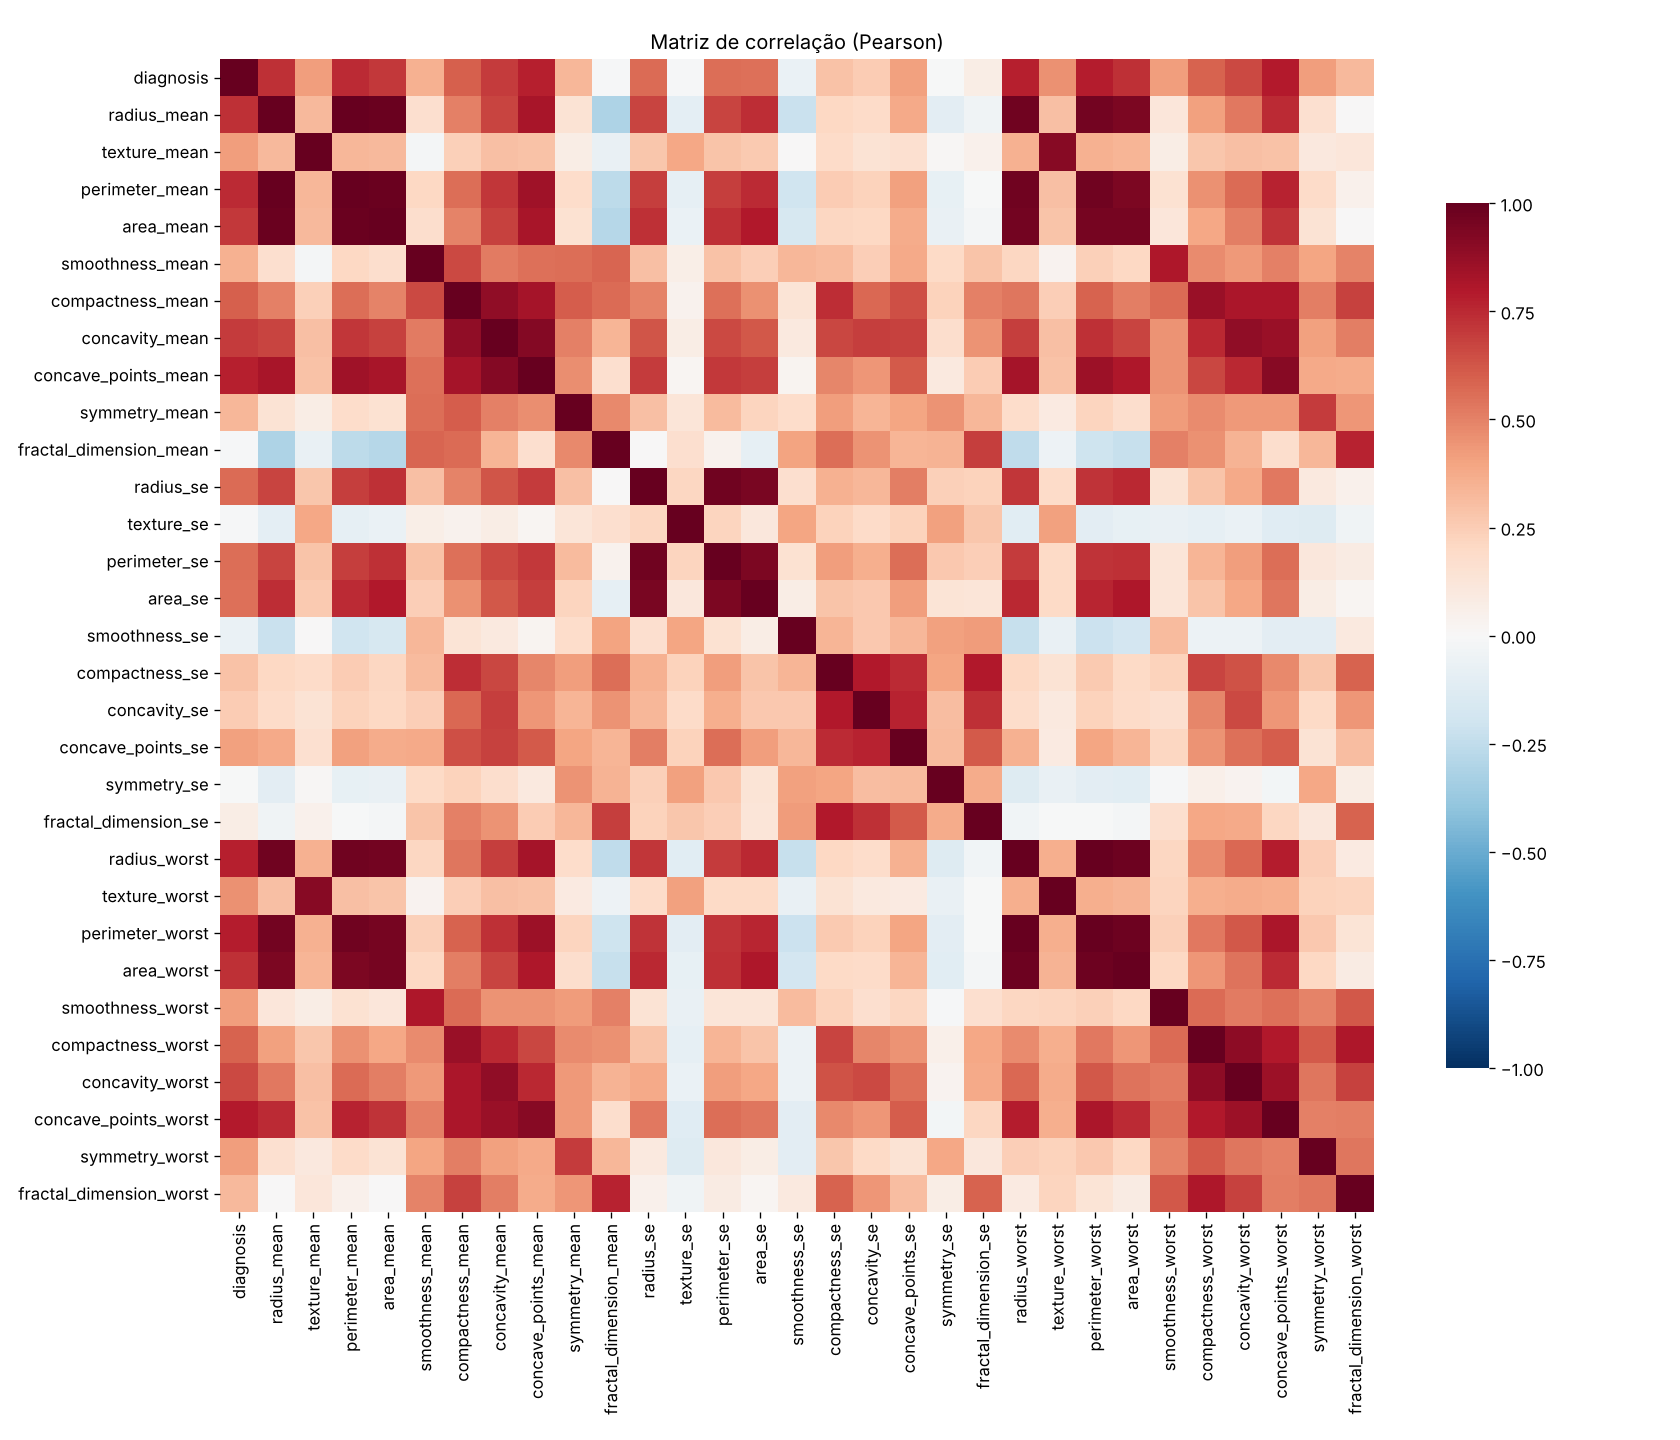

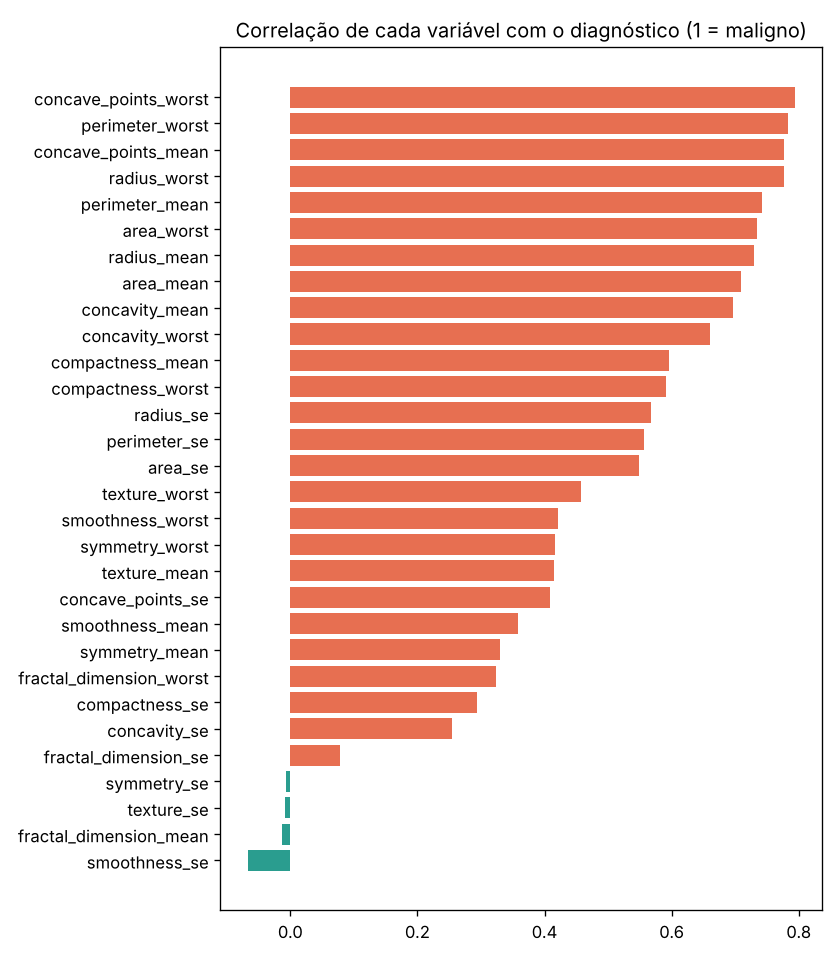

In [11]:
corr, target_corr = eda.plot_correlation(df)
display(Image(FIG / "04_correlacao.png")); display(Image(FIG / "05_correlacao_alvo.png"))

In [12]:
pairs = eda.high_correlation_pairs(corr)
print(len(pairs), "pares com |r| >= 0.9"); pd.DataFrame(pairs, columns=["var_a", "var_b", "r"]).head(10)

21 pares com |r| >= 0.9


,var_a,var_b,r
0,radius_mean,perimeter_mean,0.9980
1,radius_worst,perimeter_worst,0.9940
2,radius_mean,area_mean,0.9870
3,perimeter_mean,area_mean,0.9870
4,radius_worst,area_worst,0.9840
5,perimeter_worst,area_worst,0.9780
6,radius_se,perimeter_se,0.9730
7,radius_mean,radius_worst,0.9700
8,perimeter_mean,perimeter_worst,0.9700
9,perimeter_mean,radius_worst,0.9690


**Discussão.** As variáveis mais correlacionadas com malignidade são `concave_points_worst`, `perimeter_worst`, `concave_points_mean` e `radius_worst` (r ≈ 0,78–0,79).
Há **forte multicolinearidade**: raio, perímetro e área são quase a mesma informação (r > 0,98), como esperado geometricamente. Isso não atrapalha
árvores, mas deixa os coeficientes da Regressão Logística instáveis individualmente; a regularização L2 (parâmetro `C`) ajuda a controlar isso.
Optamos por **manter todas as variáveis** e deixar a regularização e a validação decidirem, pois a base é pequena e remover variáveis não melhorou o resultado.

## 4. Separação treino / validação / teste

In [13]:
X_train, X_val, X_test, y_train, y_val, y_test = split(df)
pd.DataFrame({"amostras": [len(y_train), len(y_val), len(y_test)],
              "% malignos": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["treino (60%)", "validação (20%)", "teste (20%)"])

,amostras,% malignos
treino (60%),341,0.3724
validação (20%),114,0.3772
teste (20%),114,0.3684


- **Treino**: ajusta os modelos.
- **Validação**: escolhe hiperparâmetros e o melhor modelo.
- **Teste**: usado **uma única vez** no final, para estimar o desempenho em pacientes novos.

## 5. Modelagem

Quatro técnicas, com perfis diferentes:

| Modelo | Por quê |
|---|---|
| Regressão Logística | Linear, rápida, probabilidades calibradas e coeficientes interpretáveis: boa referência clínica. |
| Árvore de Decisão | Regras do tipo "se… então" fáceis de explicar ao médico. |
| KNN | Classifica pelo paciente mais parecido; não paramétrico. |
| Random Forest | Conjunto de árvores, robusto a outliers e colinearidade; dá feature importance. |

Cada modelo tem uma pequena grade de hiperparâmetros. O critério de escolha na validação é **recall** e, no empate, **F1**.

In [14]:
models, val_df = modeling.tune_on_validation(X_train, y_train, X_val, y_val)
val_df

,melhores_parametros,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc
modelo,,,,,,
Regressão Logística,"{'C': 1, 'class_weight': 'balanced'}",0.9737,0.9545,0.9767,0.9655,0.9961
Árvore de Decisão,"{'class_weight': 'balanced', 'max_depth': 8, '...",0.9561,0.9130,0.9767,0.9438,0.9602
KNN,"{'n_neighbors': 7, 'weights': 'distance'}",0.9737,1.0000,0.9302,0.9639,0.9974
Random Forest,"{'class_weight': None, 'max_depth': None, 'min...",0.9737,0.9762,0.9535,0.9647,0.9918


In [15]:
best_name = val_df.sort_values(["val_recall", "val_f1", "val_roc_auc"], ascending=False).index[0]
best = models[best_name]
print("Modelo escolhido na validação:", best_name)

Modelo escolhido na validação: Regressão Logística


## 6. Avaliação no conjunto de teste

In [16]:
test_df = modeling.evaluate_on_test(models, X_test, y_test)
test_df

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
Regressão Logística,0.9737,0.9535,0.9762,0.9647,0.9954
Árvore de Decisão,0.9561,0.9512,0.9286,0.9398,0.9504
KNN,0.9474,0.9737,0.8810,0.9250,0.9843
Random Forest,0.9561,0.9744,0.9048,0.9383,0.9967


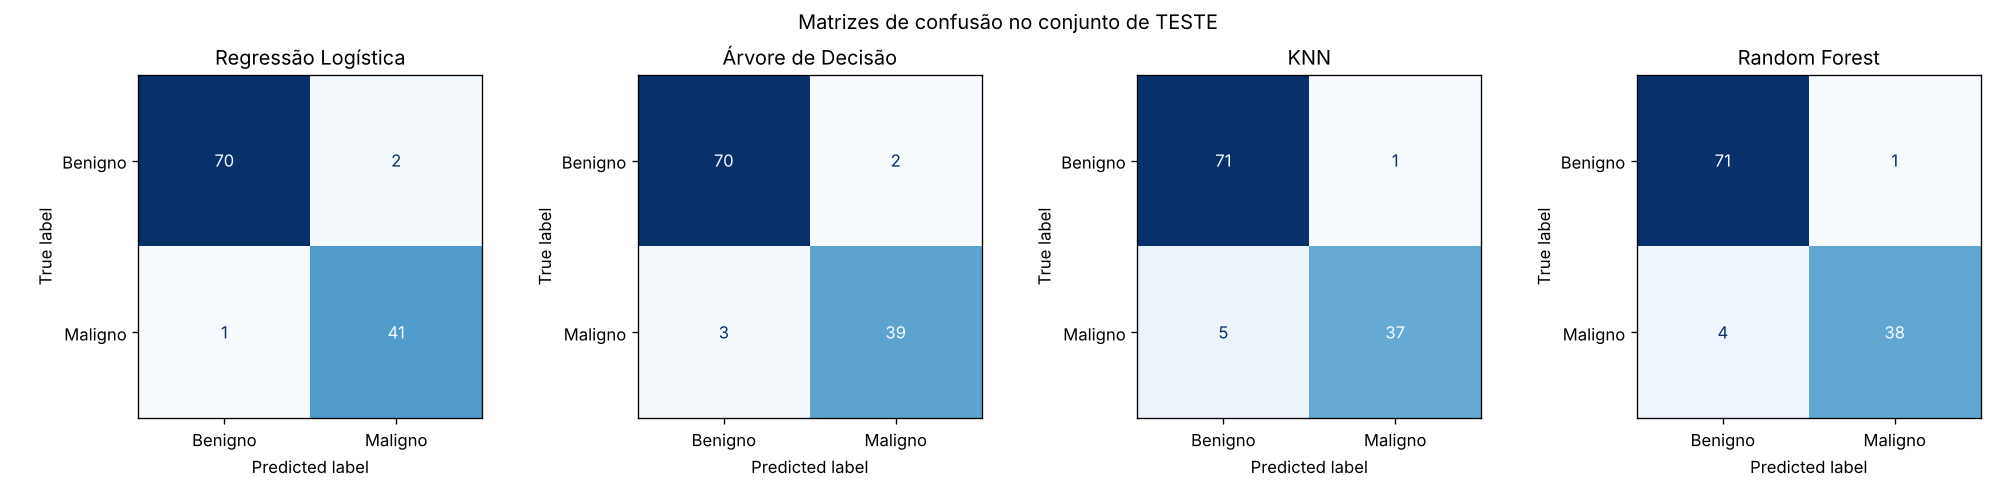

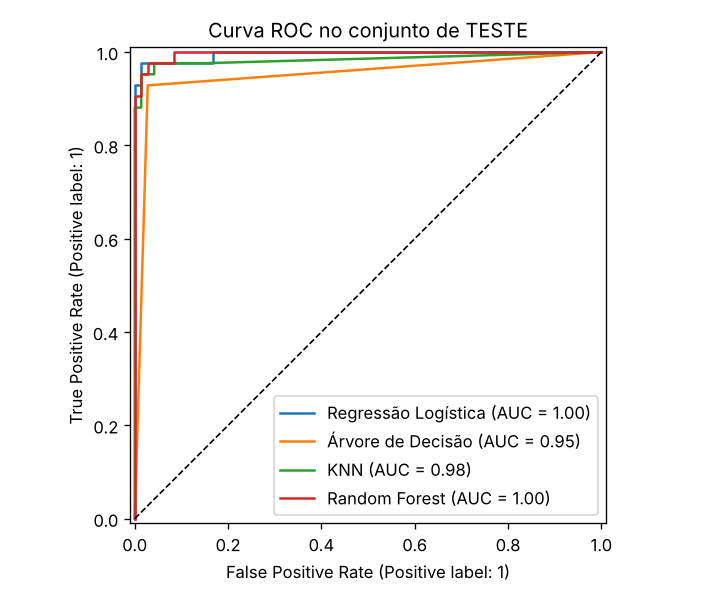

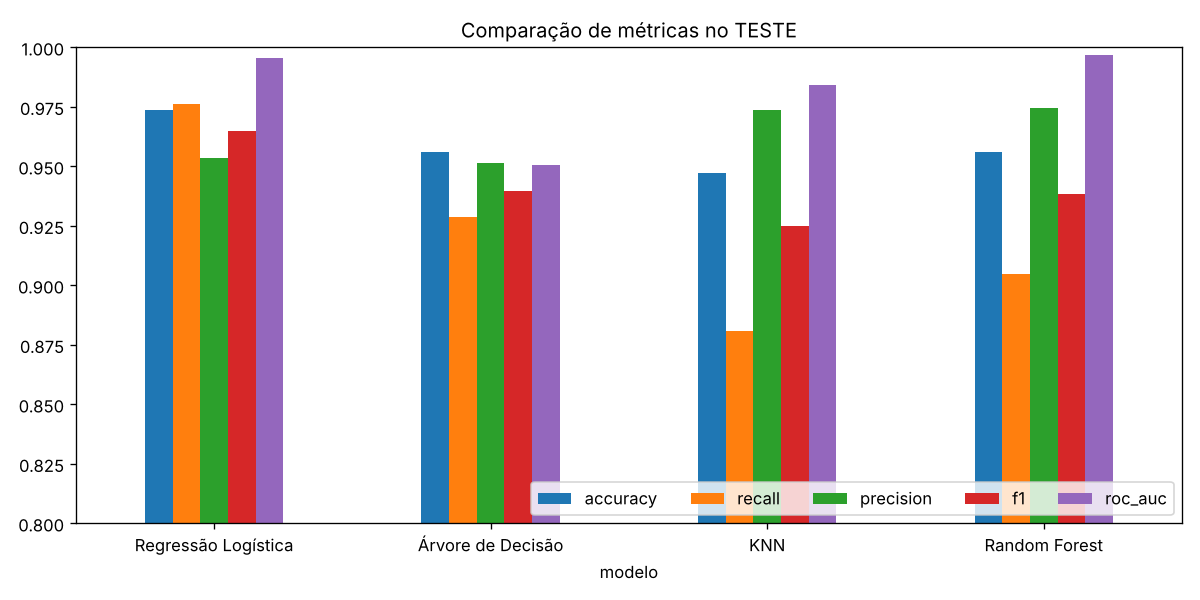

In [17]:
modeling.plot_confusion_matrices(models, X_test, y_test); display(Image(FIG / "06_matrizes_confusao.png"))
modeling.plot_roc(models, X_test, y_test); display(Image(FIG / "07_curva_roc.png"))
modeling.plot_metric_comparison(test_df); display(Image(FIG / "08_comparacao_metricas.png"))

**Escolha da métrica.**
- **Accuracy** sozinha engana com classes desbalanceadas (um modelo que diz sempre "benigno" acerta ~63%).
- **Recall (sensibilidade) da classe maligna** é a mais importante: mede quantos cânceres o modelo encontra. Um falso negativo é muito mais grave que um falso positivo.
- **Precision** mede quantos alertas são realmente câncer (falsos positivos geram exames extras e ansiedade, mas a biópsia confirma).
- **F1** equilibra os dois; **ROC-AUC** mede a capacidade de separar as classes em qualquer limiar.

**Resultado.** A **Regressão Logística** teve o melhor equilíbrio no teste: recall ≈ 0,976 (41 de 42 malignos encontrados), F1 ≈ 0,965 e acurácia ≈ 97,4%.
KNN e Random Forest têm AUC alta e quase nenhum falso positivo, mas deixam passar 4–5 cânceres no limiar padrão de 0,5.

### Ajuste do limiar de decisão
Em triagem, podemos baixar o limiar para ganhar sensibilidade. O limiar é escolhido **na validação** (maior limiar com recall ≥ 98%) e só depois aplicado ao teste.

In [18]:
thr, thr_df = modeling.threshold_analysis(best, X_val, y_val, X_test, y_test)
print("Limiar escolhido:", thr); thr_df

Limiar escolhido: 0.15


,accuracy,precision,recall,f1,roc_auc
limiar,,,,,
0.1500,0.9211,0.8367,0.9762,0.9011,0.9954
0.5000,0.9737,0.9535,0.9762,0.9647,0.9954


Com este conjunto de teste o recall já era máximo para o modelo (o único câncer perdido recebeu probabilidade de apenas ~10%), então baixar o limiar
só aumentou falsos positivos. Conclusão prática: o limiar deve ser **definido junto com a equipe clínica**, conforme o custo aceitável de exames extras.

## 7. Interpretação dos resultados

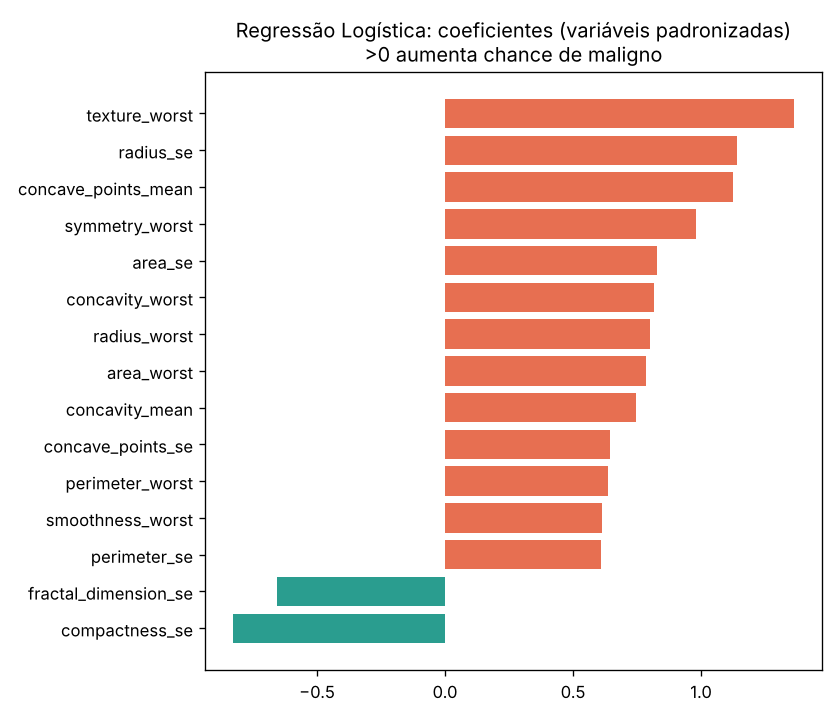

In [19]:
coef = interpretation.logistic_coefficients(models["Regressão Logística"])
display(Image(FIG / "09_coeficientes_logistica.png"))

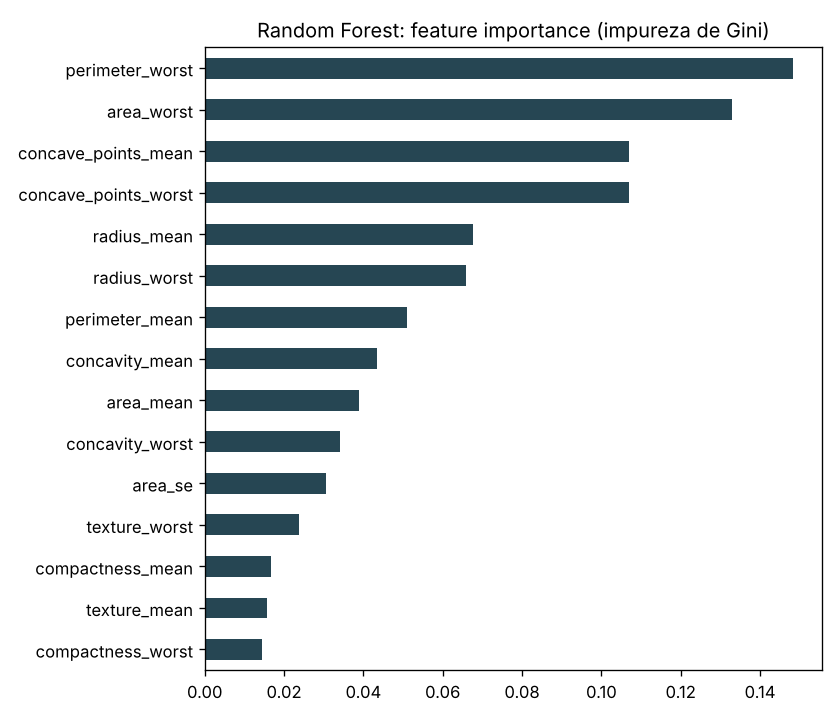

In [20]:
rf_imp = interpretation.tree_importance(models["Random Forest"])
display(Image(FIG / "10_importancia_random_forest.png"))

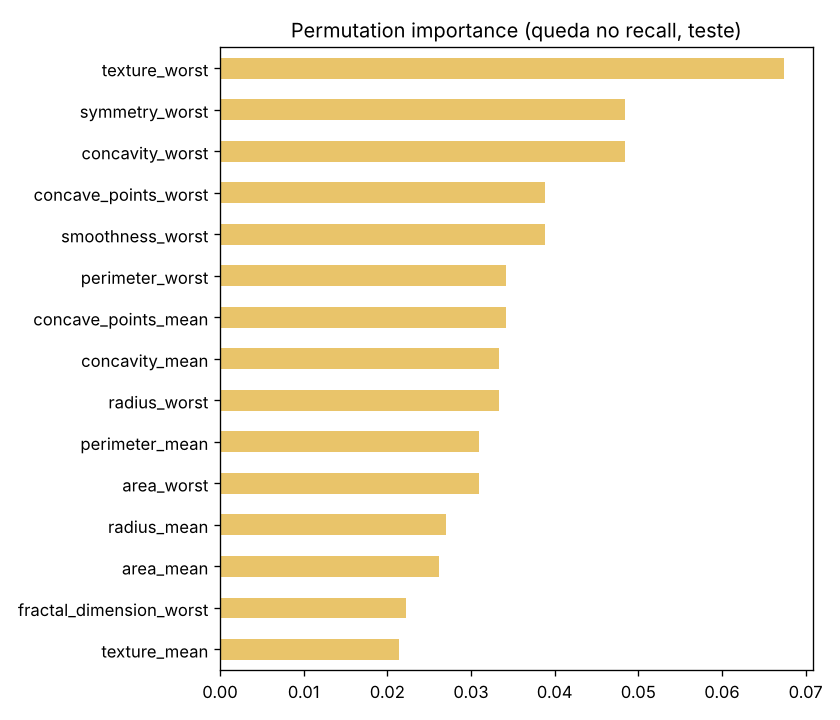

In [21]:
perm = interpretation.permutation(best, X_test, y_test)
display(Image(FIG / "11_permutation_importance.png"))

### SHAP
SHAP decompõe cada previsão na contribuição de cada variável. Pontos vermelhos = valor alto da variável; à direita = empurra para **maligno**.

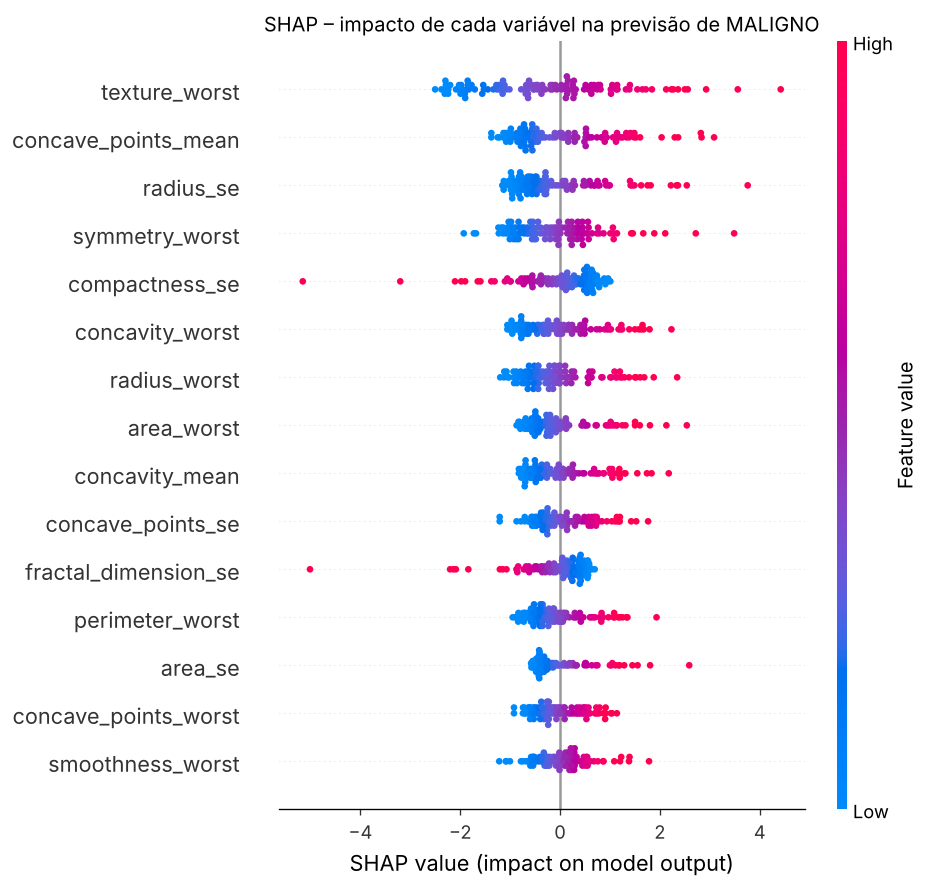

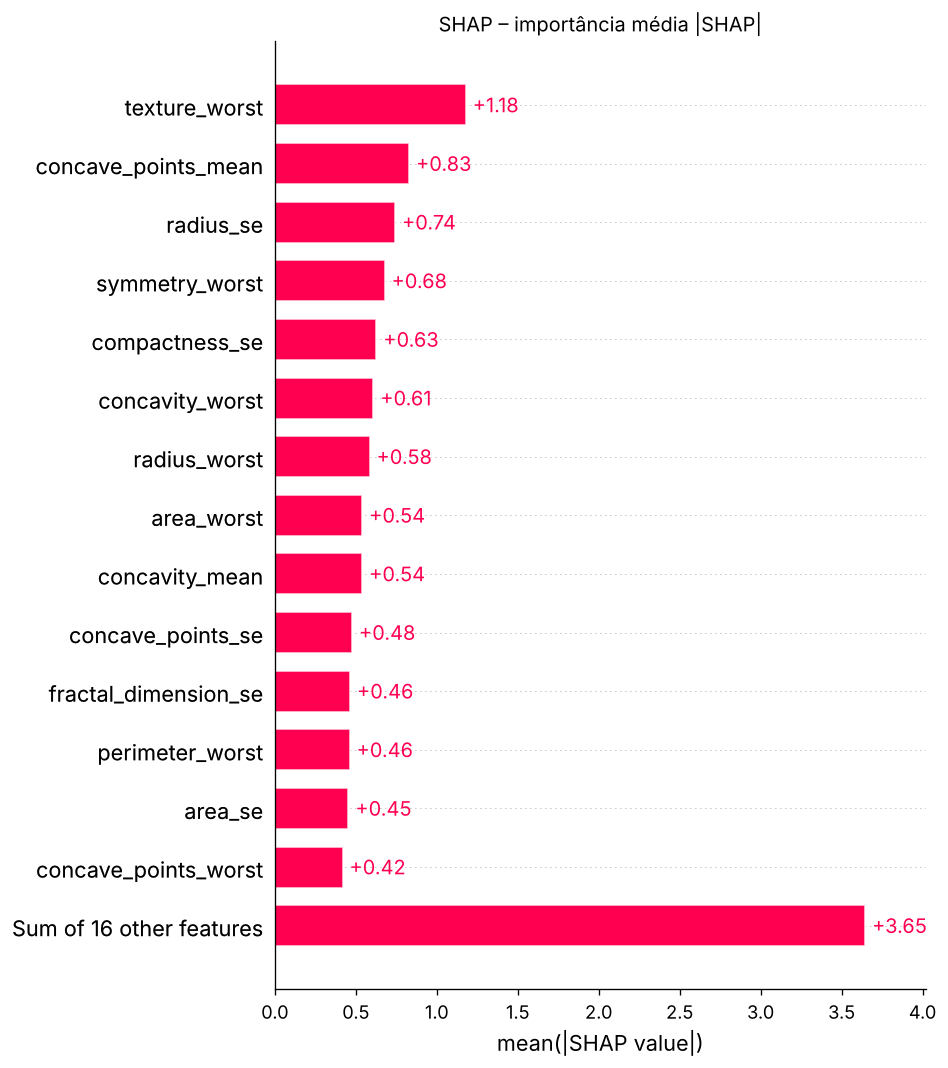

texture_worst         1.1790
concave_points_mean   0.8288
radius_se             0.7421
symmetry_worst        0.6775
compactness_se        0.6267
concavity_worst       0.6079
radius_worst          0.5847
area_worst            0.5393
concavity_mean        0.5392
concave_points_se     0.4763
dtype: float64

In [22]:
kind = "linear" if best_name == "Regressão Logística" else "tree"
model_for_shap = best if best_name != "KNN" else models["Random Forest"]
if best_name == "KNN": kind = "tree"
sv, shap_imp = interpretation.shap_analysis(model_for_shap, X_train, X_test, kind)
display(Image(FIG / "12_shap_summary.png")); display(Image(FIG / "13_shap_bar.png"))
shap_imp.head(10)

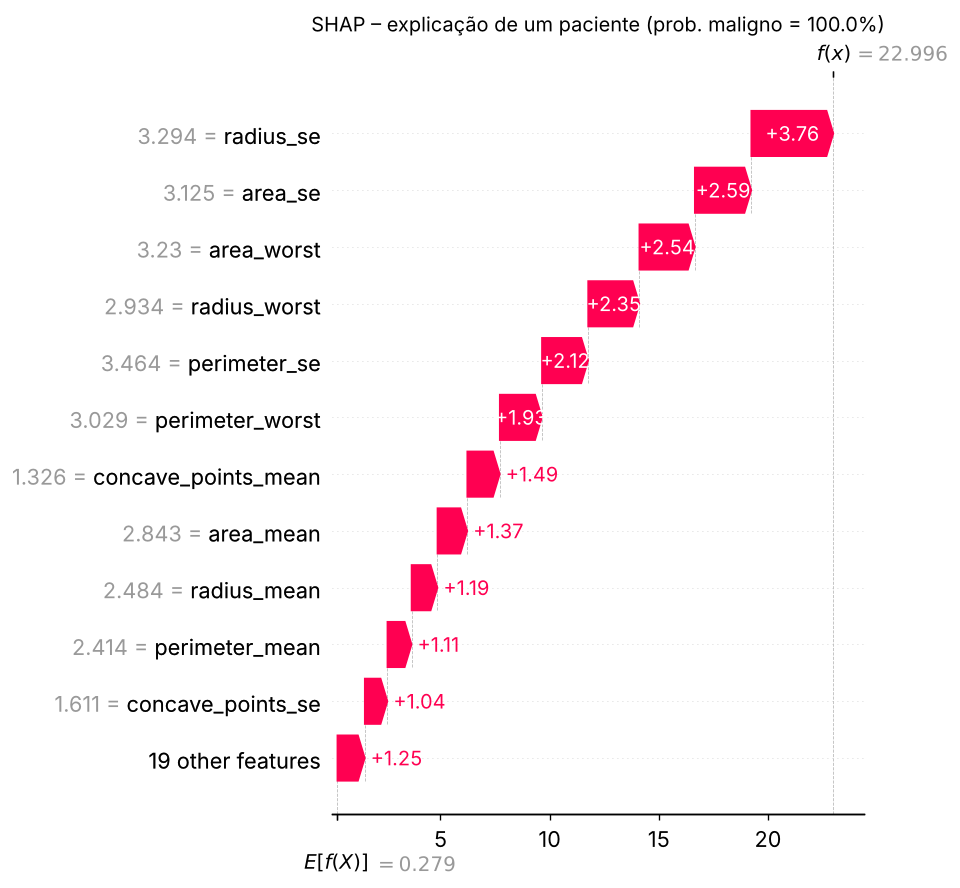

In [23]:
display(Image(FIG / "14_shap_paciente.png"))

**Leitura.**
- Os dois métodos concordam que **tamanho do tumor** (raio/perímetro/área, sobretudo os valores "worst") e **pontos côncavos / concavidade** são os sinais mais fortes de malignidade, o que coincide com critérios citopatológicos (núcleos maiores e contornos irregulares).
- Na Regressão Logística, `texture_worst` aparece no topo do SHAP: textura irregular (variação de tons de cinza) eleva o risco.
- Algumas variáveis `_se` (ex.: `compactness_se`, `fractal_dimension_se`) têm sinal negativo: por causa da colinearidade, o modelo as usa como "correção" das variáveis correlacionadas. Por isso é melhor interpretar **grupos** de variáveis do que um coeficiente isolado.
- O gráfico *waterfall* mostra a explicação de **um paciente**: é o tipo de visualização que o médico veria ao lado da probabilidade.

## 8. Discussão crítica: o modelo pode ser usado na prática?

**Pontos fortes.** Desempenho alto e consistente (AUC > 0,99, recall ≈ 97–98%), modelo simples, rápido e explicável com SHAP.

**Limitações.**
- Base **pequena (569 casos)** e de **uma única instituição** (Universidade de Wisconsin, anos 90); o desempenho precisa ser validado com dados do hospital.
- As variáveis dependem de um processo específico de digitalização e segmentação das imagens de PAAF; mudanças de equipamento ou protocolo podem degradar o modelo (*data drift*).
- Um câncer ainda passou despercebido no teste. **Nenhum modelo substitui a biópsia/histopatologia.**
- O intervalo de confiança das métricas é largo com 114 casos de teste; a variação entre divisões deve ser acompanhada.

**Como usar.** Como **ferramenta de triagem e segunda opinião**:
1. o sistema calcula a probabilidade de malignidade e mostra as variáveis que mais pesaram (SHAP);
2. casos de alta probabilidade são **priorizados** na fila do patologista;
3. o limiar é ajustado com a equipe clínica para maximizar a sensibilidade;
4. **o médico sempre tem a palavra final**, e o modelo é monitorado e re-treinado periodicamente, com auditoria de erros.